# Brick 9 - evaluation

**Gate:** Per-class metrics and confusion matrices for Split G and Split R, side by side.

The narrative report for this brick is `reports/metrics_S.md`. The cells below load the saved artifacts; they do not retrain anything.

In [1]:
import json
from pathlib import Path
from IPython.display import Image, display, Markdown
import pandas as pd

ROOT = Path.cwd().parent
REPORTS = ROOT / "reports"
FIGURES = ROOT / "figures"

def md(name):
    p = REPORTS / name
    display(Markdown(p.read_text(encoding="utf-8"))) if p.exists() else print("missing", name)

def js(name, keys=None, indent=2):
    p = REPORTS / name
    if not p.exists():
        print("missing", name); return None
    d = json.loads(p.read_text(encoding="utf-8"))
    print(json.dumps({k: d[k] for k in keys} if keys else d, indent=indent)[:6000])
    return d


# Brick 9 - evaluation (Mode S)

Frozen model: XGBoost.

## Split G (headline)

- test pairs 61,592; test drugs 55
- accuracy 0.4477; macro-F1 0.4446

|   class |   precision |   recall |     f1 |   support |
|--------:|------------:|---------:|-------:|----------:|
|       0 |      0.3717 |   0.4119 | 0.3908 |     17336 |
|       1 |      0.5674 |   0.3985 | 0.4682 |     23789 |
|       2 |      0.4267 |   0.5352 | 0.4748 |     20467 |

|        |   pred 0 |   pred 1 |   pred 2 |
|:-------|---------:|---------:|---------:|
| true 0 |     7140 |     4042 |     6154 |
| true 1 |     5743 |     9481 |     8565 |
| true 2 |     6326 |     3188 |    10953 |

## Split R (paper-style, optimistic)

- test pairs 61,488; test drugs 447
- accuracy 0.7974; macro-F1 0.7950

|   class |   precision |   recall |     f1 |   support |
|--------:|------------:|---------:|-------:|----------:|
|       0 |      0.7944 |   0.8537 | 0.823  |     20326 |
|       1 |      0.8167 |   0.8673 | 0.8412 |     20611 |
|       2 |      0.7773 |   0.6716 | 0.7206 |     20551 |

|        |   pred 0 |   pred 1 |   pred 2 |
|:-------|---------:|---------:|---------:|
| true 0 |    17353 |      878 |     2095 |
| true 1 |      876 |    17876 |     1859 |
| true 2 |     3614 |     3134 |    13803 |


# Brick 9 - evaluation (Mode P)

Frozen model: RandomForest.

## Split G (headline)

- test pairs 50,700; test drugs 169
- accuracy 0.4210; macro-F1 0.3794

|   class |   precision |   recall |     f1 |   support |
|--------:|------------:|---------:|-------:|----------:|
|       0 |      0.5689 |   0.5366 | 0.5523 |     25800 |
|       1 |      0.2481 |   0.3648 | 0.2953 |      8700 |
|       2 |      0.3187 |   0.267  | 0.2906 |     16200 |

|        |   pred 0 |   pred 1 |   pred 2 |
|:-------|---------:|---------:|---------:|
| true 0 |    13843 |     4998 |     6959 |
| true 1 |     3238 |     3174 |     2288 |
| true 2 |     7251 |     4623 |     4326 |

## Split R (paper-style, optimistic)

- test pairs 50,637; test drugs 1,359
- accuracy 0.6681; macro-F1 0.6427

|   class |   precision |   recall |     f1 |   support |
|--------:|------------:|---------:|-------:|----------:|
|       0 |      0.7975 |   0.6757 | 0.7316 |     28504 |
|       1 |      0.4981 |   0.731  | 0.5925 |      8086 |
|       2 |      0.5921 |   0.6164 | 0.604  |     14047 |

|        |   pred 0 |   pred 1 |   pred 2 |
|:-------|---------:|---------:|---------:|
| true 0 |    19260 |     4126 |     5118 |
| true 1 |     1329 |     5911 |      846 |
| true 2 |     3560 |     1829 |     8658 |


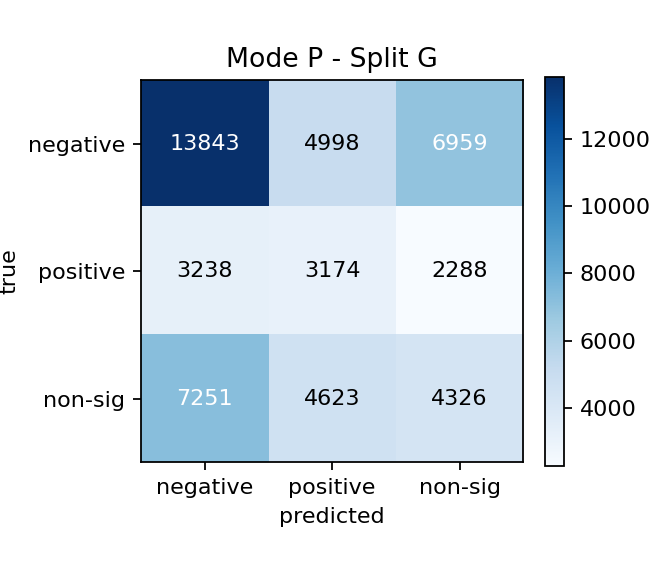

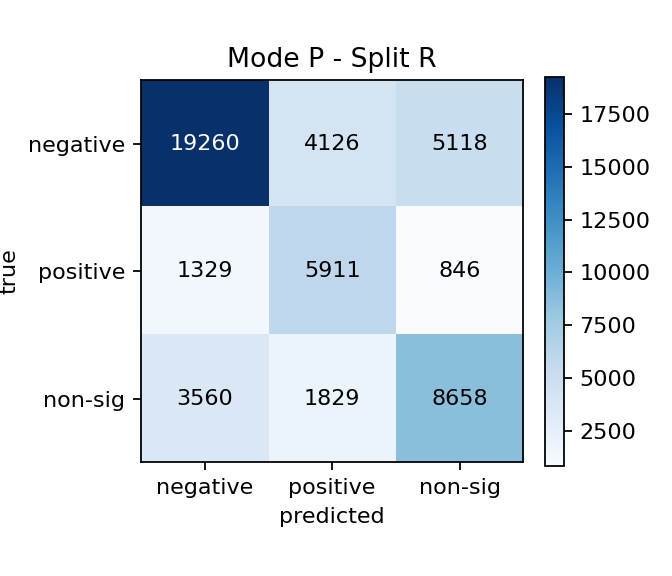

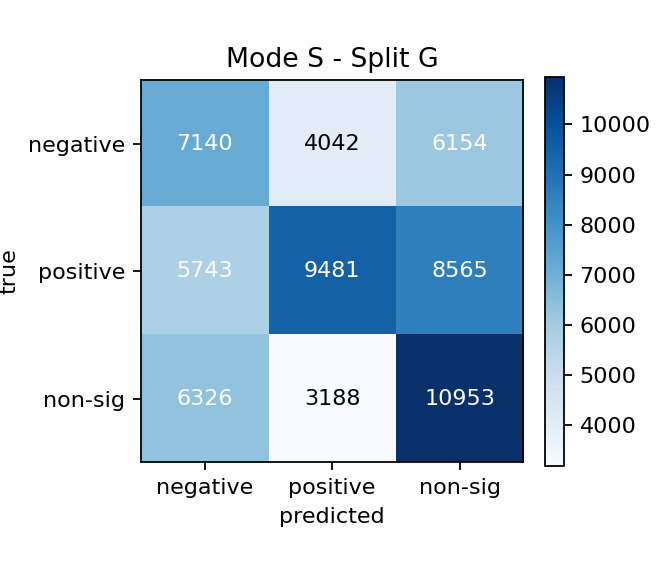

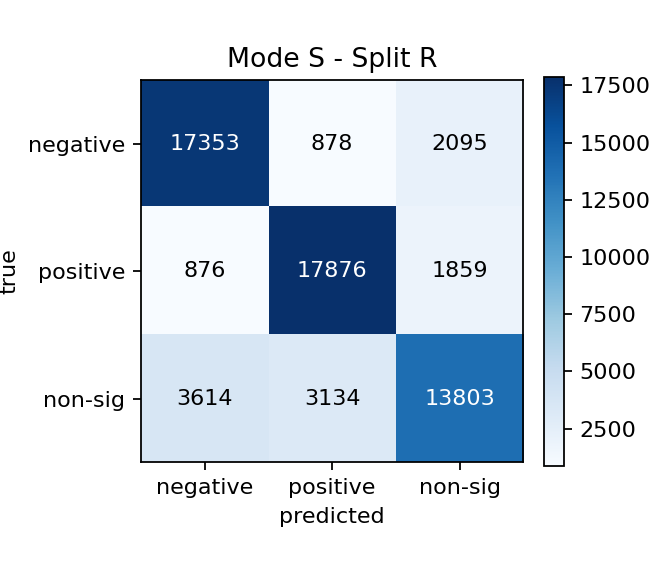

In [2]:
md('metrics_S.md'); md('metrics_P.md')
for f in sorted(FIGURES.glob('cm_*.png')): display(Image(filename=str(f)))

In [3]:
# Reproduce this brick from scratch (long running):
# !cd .. && PYTHONPATH=src python src/brick9_*.py